# 유재윤 RNN 담당 결과 재현

R01·R02·R03 × seed 2026·2027·2028의 9회 결과를 확인한다. 공식 test는 미평가다. 모델과 입력 데이터는 RNN Release ZIP에 포함되어 있다. 새 학습 결과가 아니라 보존한 모델·예측의 재현 확인이다.

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown, Image
from src.adapters.processed_npz import load_processed_data
data = load_processed_data(ROOT/"data/processed_data.npz", ROOT/"data/preprocess.npz")
print("학습 입력:", data.x_fit.shape, "검증 입력:", data.x_validation.shape)
print("검증 피험자:", sorted(set(data.validation_subjects.tolist())))
print("학습 통계 한 번 적용 · 공식 test 미평가")

학습 입력: (5577, 128, 9) 검증 입력: (1775, 128, 9)
검증 피험자: [1, 6, 14, 21, 23]
학습 통계 한 번 적용 · 공식 test 미평가


## 수식 확인

작은 RNN의 중심차분을 자동미분과 비교한다. 장기 기억이나 기울기 소실을 입증하는 실험은 아니다.

In [2]:
from src.rnn_math_checks import run
check = run()
assert check["passed"]
print("확인한 파라미터:", check["checked_parameters"])
print("최대 절대 오차:", check["max_absolute_error"])

확인한 파라미터: 30
최대 절대 오차: 1.8750136859813082e-11


## RNN 9회 결과

평균과 표준편차는 고정 피험자 분할에서 세 학습 seed에 대해 계산했다. 기준 R01과 선택 R02를 구분한다.

| 조건 | 검증 정확도 평균 | 검증 Macro F1 평균 ± 표본 SD |
|---|---:|---:|
| R01 | 0.7356 | 0.7191 ± 0.0586 |
| R02 | 0.7855 | 0.7715 ± 0.0675 |
| R03 | 0.7654 | 0.7525 ± 0.0804 |


선택 조건: R02 · 설명 seed: 2026


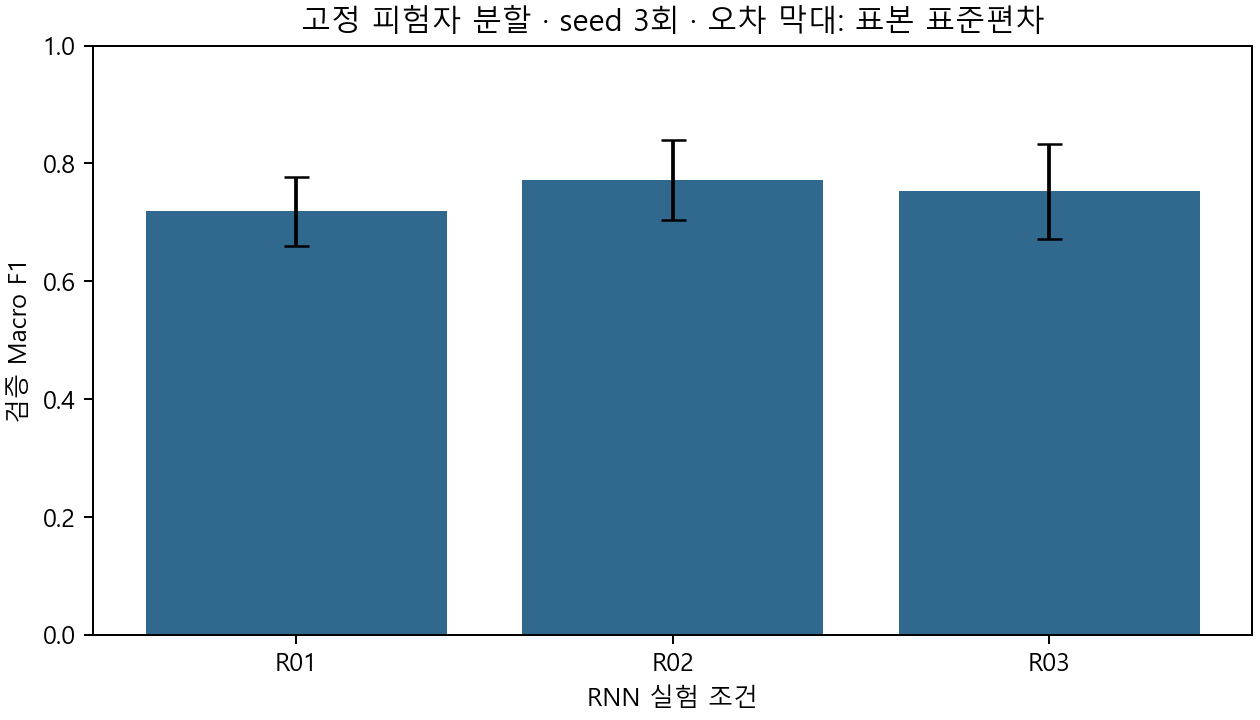

In [3]:
analysis = json.loads((ROOT/"reports/rnn/analysis.json").read_text(encoding="utf-8"))
assert len(analysis["runs"]) == 9
assert {r["model"] for r in analysis["runs"]} == {"rnn"}
table = "| 조건 | 검증 정확도 평균 | 검증 Macro F1 평균 ± 표본 SD |\n|---|---:|---:|\n"
for row in analysis["summary"]:
    table += f"| {row['experiment']} | {row['accuracy_mean']:.4f} | {row['macro_f1_mean']:.4f} ± {row['macro_f1_sd']:.4f} |\n"
display(Markdown(table))
print("선택 조건:", analysis["selected_rnn"], "· 설명 seed: 2026")
display(Image(filename=str(ROOT/"reports/rnn/figures/validation_comparison.png"), width=700))

## 선택 모델 복원

저장 모델을 검증 1,775개 전체에서 다시 불러와 원 예측과 대조한다. 학습 기록은 덮어쓰지 않는다.

검증 전체 모델 복원 통과: R02_seed2026


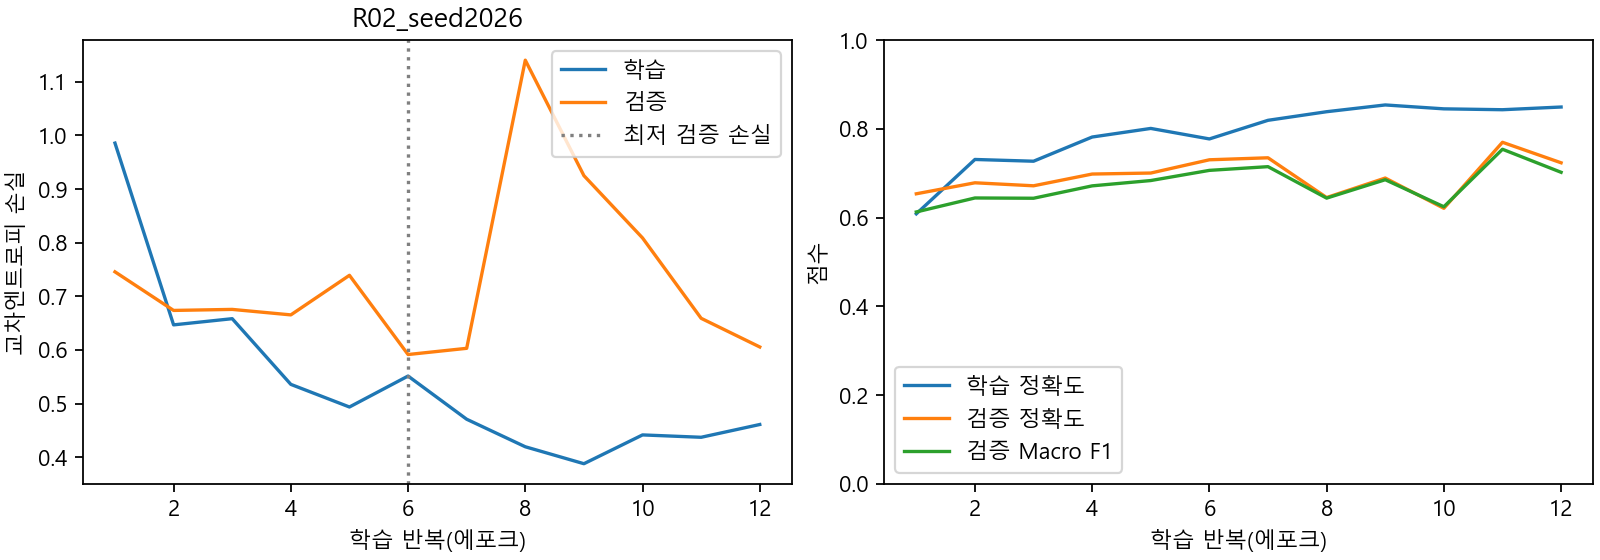

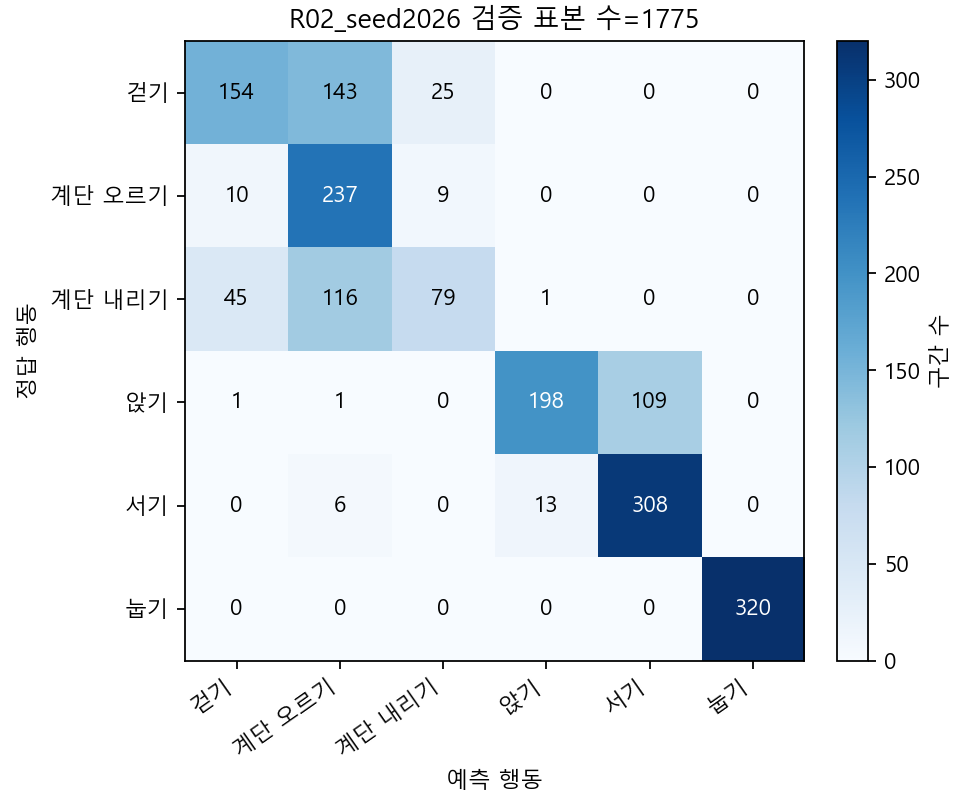

In [4]:
import subprocess
run_name = analysis["selected_rnn"] + "_seed2026"
target = ROOT/"reports/rnn/notebook_model_recheck.json"
command = [sys.executable, "-m", "src.verify_bundle", "--processed-data", str(ROOT/"data/processed_data.npz"), "--preprocess-stats", str(ROOT/"data/preprocess.npz"), "--run-directory", str(ROOT/"runs/rnn"/run_name), "--report", str(target)]
result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
assert result.returncode == 0, "모델 복원 검증 실패"
recheck = json.loads(target.read_text(encoding="utf-8"))
assert recheck["passed"]
print("검증 전체 모델 복원 통과:", run_name)
display(Image(filename=str(ROOT/f"reports/rnn/figures/{run_name}_history.png"), width=900))
display(Image(filename=str(ROOT/f"reports/rnn/figures/{run_name}_confusion.png"), width=600))

## 오분류·정분류 파형 대조

가장 큰 혼동의 원본 ID가 빠른 오류 3개를 같은 피험자·같은 정답의 서로 다른 성공 표본과 대조했다. 무작위 대표 표본이 아니며 원인을 확정하지 않는다.

오류 표본: train:000082 정분류 표본: train:000078


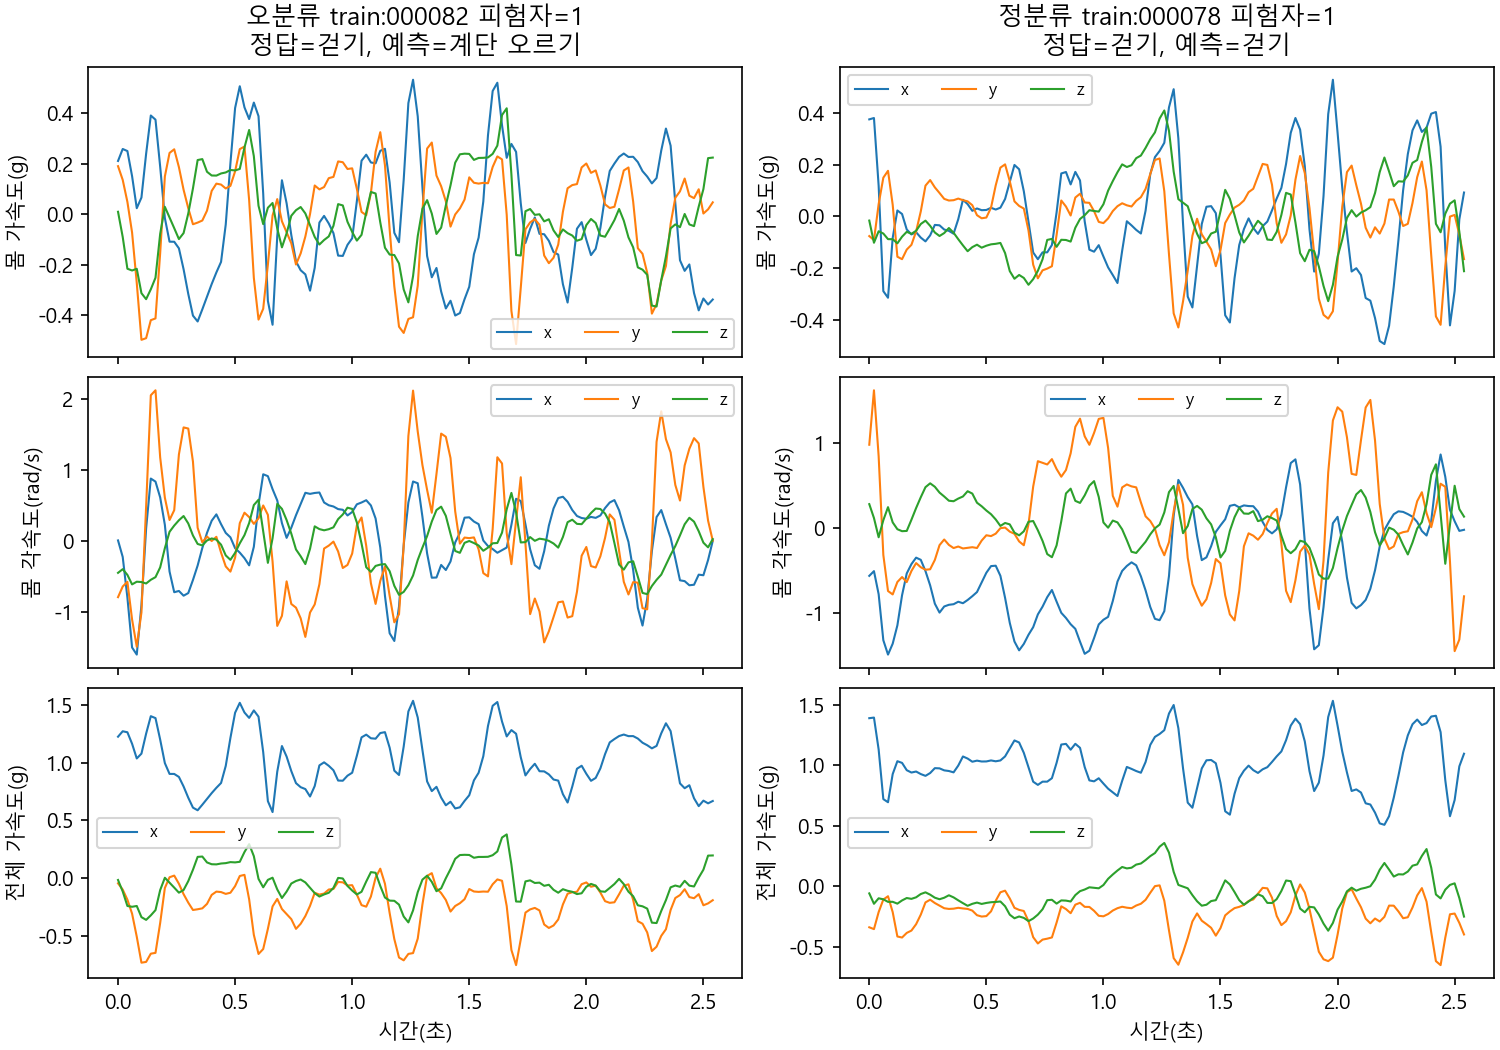

오류 표본: train:000086 정분류 표본: train:000080


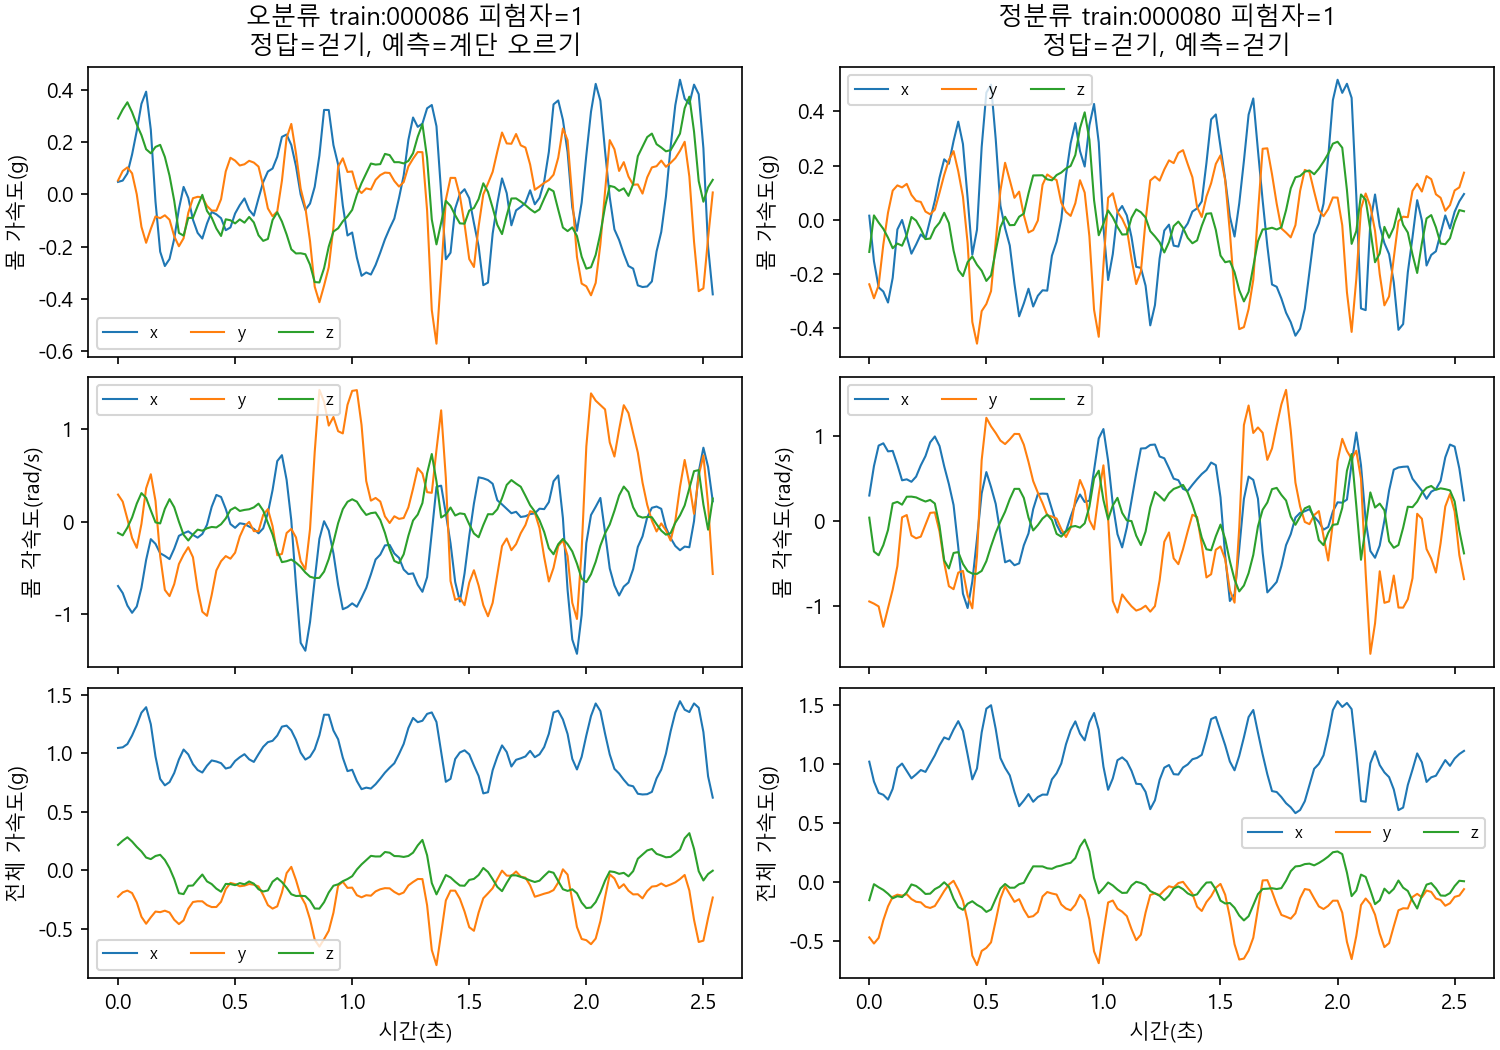

오류 표본: train:000090 정분류 표본: train:000083


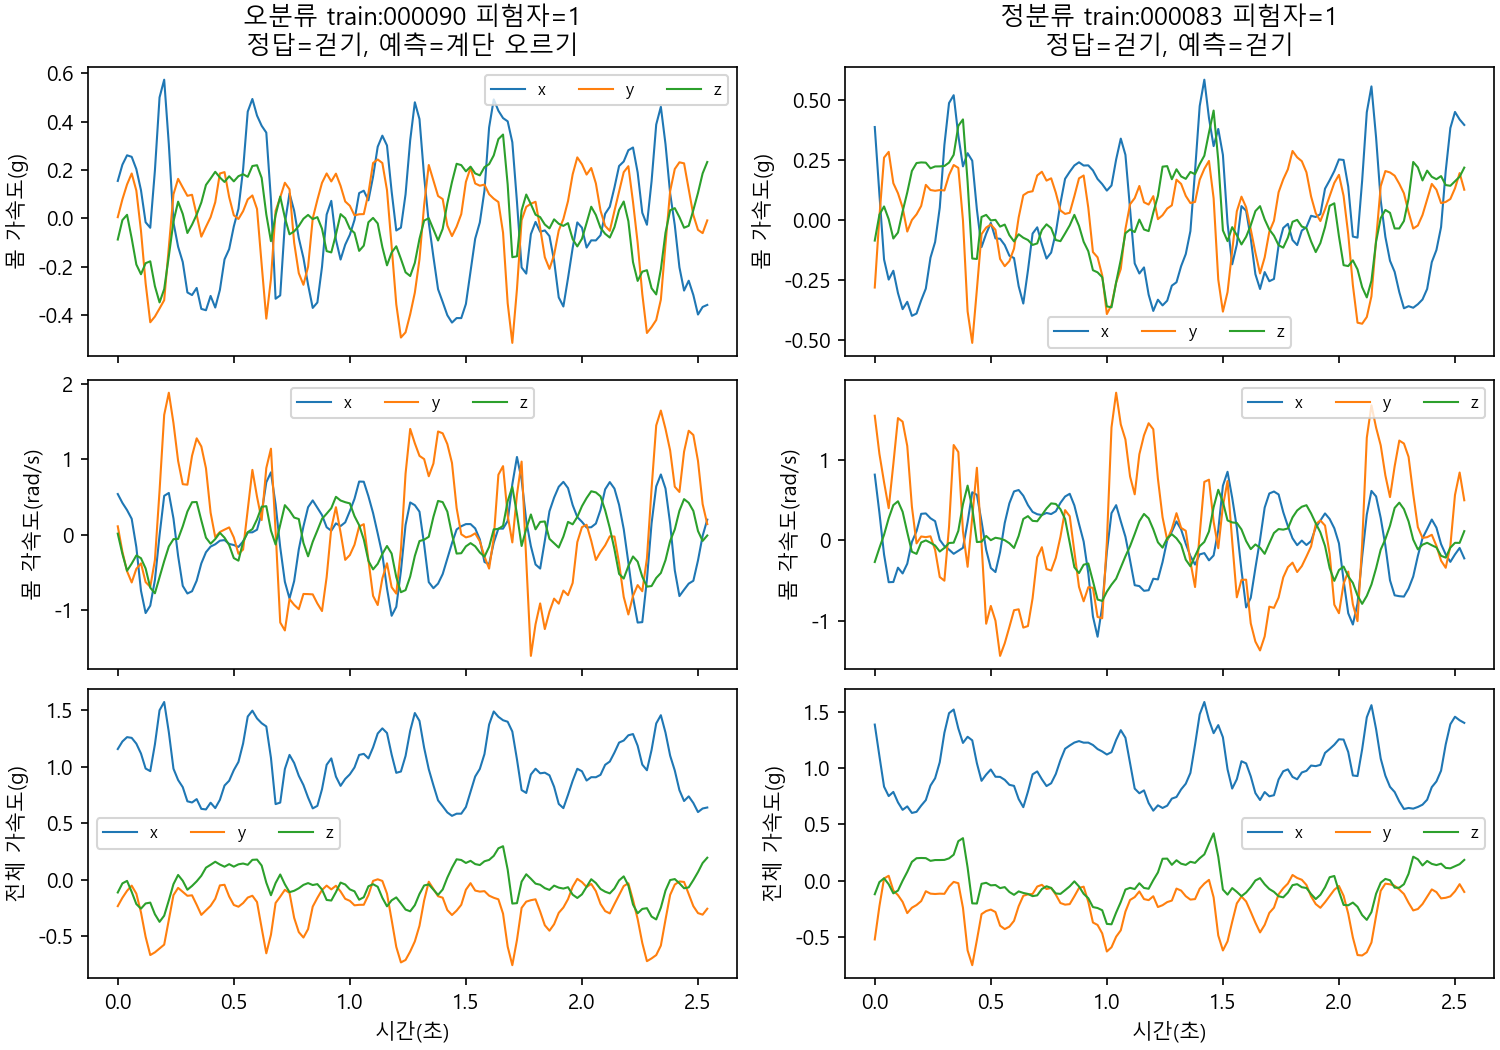

In [5]:
cases = json.loads((ROOT/"reports/rnn/error_success_cases.json").read_text(encoding="utf-8"))
assert len(cases["cases"]) == 3
for case in cases["cases"]:
    print("오류 표본:", case["error_sample_id"], "정분류 표본:", case["success_sample_id"])
    display(Image(filename=str(ROOT/f"reports/rnn/figures/error_success_pair_{case['pair']}.png"), width=900))

공식 test·팀 전체 모델 비교·최종 통합 발표는 공동 조건과 최종 대상이 확정된 뒤 진행한다.